In [ ]:
from pathlib import Path
import os
PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "app.py").is_file())
os.chdir(PROJECT_DIR)
Path("reports/figures").mkdir(parents=True, exist_ok=True)
Path("data/processed").mkdir(parents=True, exist_ok=True)


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import string

# Pastikan working directory selalu di folder projek (bebas dari lokasi server Jupyter)
os.chdir(PROJECT_DIR)
print(f"Working directory: {os.getcwd()}")

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# 1. Load Dataset BISINDO & SIBI
df_bisindo = pd.read_csv("data/raw/BISINDO/Alphabet/landmarks_train.csv")
df_sibi = pd.read_csv("data/processed/sibi_landmarks.csv")

# Standardisasi Label BISINDO: ubah angka 0-25 menjadi huruf 'A'-'Z' agar seragam
mapping_abjad = {i: chr(ord('A') + i) for i in range(26)}
df_bisindo['label'] = df_bisindo['label'].map(mapping_abjad)

print(f"Data BISINDO dimuat : {df_bisindo.shape[0]} baris, {df_bisindo.shape[1]} kolom")
print(f"Data SIBI dimuat    : {df_sibi.shape[0]} baris, {df_sibi.shape[1]} kolom")

Working directory: D:\2. IPB\Semester 5\Machine Learning\Projek
Data BISINDO dimuat : 7558 baris, 127 kolom
Data SIBI dimuat    : 1226 baris, 64 kolom


In [2]:
def check_data_health(df, name):
    missing = df.isnull().sum().sum()
    duplicates = df.duplicated().sum()
    print(f"=== Pemeriksaan Kualitas Data: {name} ===")
    print(f"- Total Missing Values : {missing}")
    print(f"- Total Baris Duplikat : {duplicates}")
    print("-" * 40)

check_data_health(df_sibi, "SIBI")
check_data_health(df_bisindo, "BISINDO")

=== Pemeriksaan Kualitas Data: SIBI ===
- Total Missing Values : 0
- Total Baris Duplikat : 5
----------------------------------------
=== Pemeriksaan Kualitas Data: BISINDO ===
- Total Missing Values : 0
- Total Baris Duplikat : 1139
----------------------------------------


C:\Users\hilma\AppData\Local\Temp\ipykernel_1232\813434756.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_sibi, x='label', order=order_abjad, ax=axes[0], palette="Blues_d")
C:\Users\hilma\AppData\Local\Temp\ipykernel_1232\813434756.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_bisindo, x='label', order=order_abjad, ax=axes[1], palette="Greens_d")


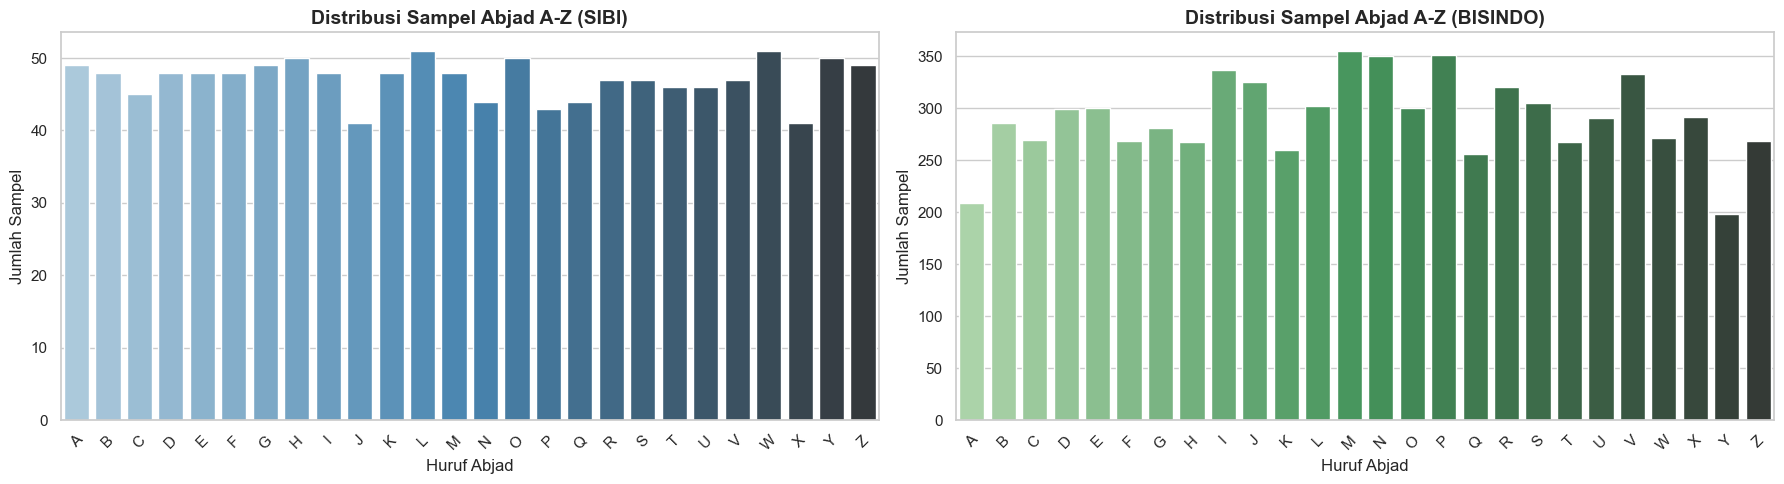

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# Plot Distribusi SIBI
order_abjad = list(string.ascii_uppercase)
sns.countplot(data=df_sibi, x='label', order=order_abjad, ax=axes[0], palette="Blues_d")
axes[0].set_title("Distribusi Sampel Abjad A-Z (SIBI)", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Huruf Abjad")
axes[0].set_ylabel("Jumlah Sampel")
axes[0].tick_params(axis='x', rotation=45)

# Plot Distribusi BISINDO
sns.countplot(data=df_bisindo, x='label', order=order_abjad, ax=axes[1], palette="Greens_d")
axes[1].set_title("Distribusi Sampel Abjad A-Z (BISINDO)", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Huruf Abjad")
axes[1].set_ylabel("Jumlah Sampel")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig("reports/figures/distribusi_kelas_abjad.png", dpi=300)
plt.show()

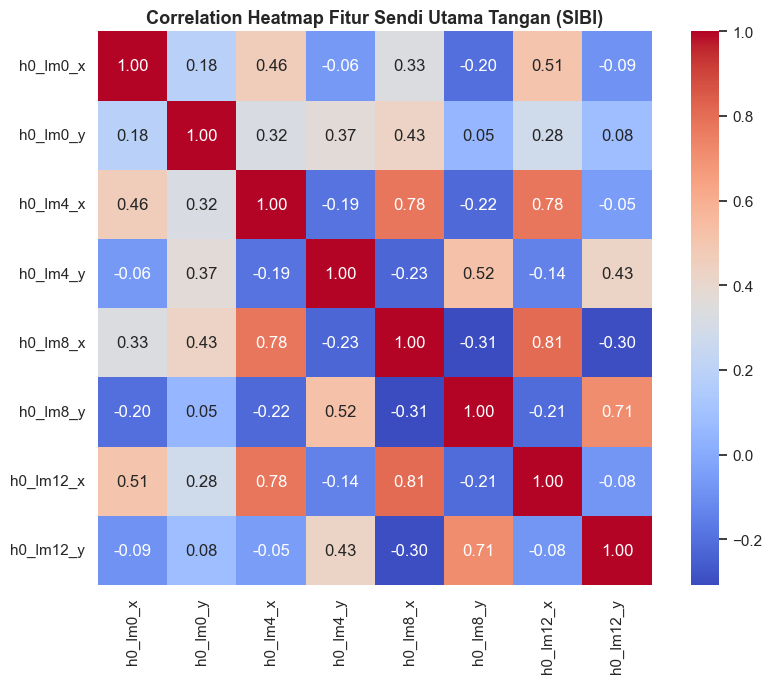

In [4]:
# Ambil beberapa sendi representatif: Wrist (lm0), Thumb_Tip (lm4), Index_Tip (lm8), Middle_Tip (lm12)
sample_features = [
    'h0_lm0_x', 'h0_lm0_y', 
    'h0_lm4_x', 'h0_lm4_y', 
    'h0_lm8_x', 'h0_lm8_y', 
    'h0_lm12_x', 'h0_lm12_y'
]

plt.figure(figsize=(9, 7))
corr_matrix = df_sibi[sample_features].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True)
plt.title("Correlation Heatmap Fitur Sendi Utama Tangan (SIBI)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("reports/figures/correlation_heatmap_sibi.png", dpi=300)
plt.show()

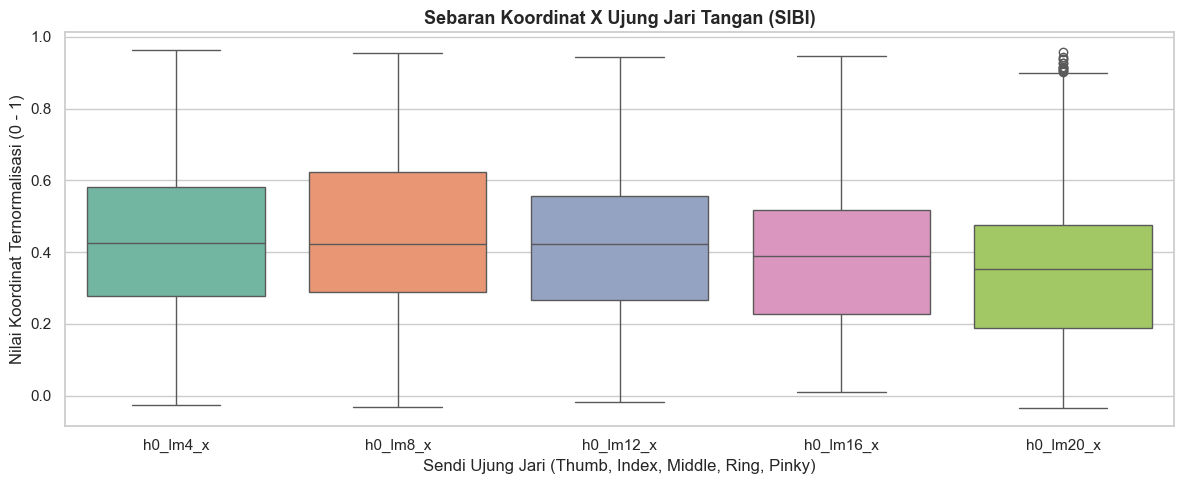

In [5]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_sibi[['h0_lm4_x', 'h0_lm8_x', 'h0_lm12_x', 'h0_lm16_x', 'h0_lm20_x']], palette="Set2")
plt.title("Sebaran Koordinat X Ujung Jari Tangan (SIBI)", fontsize=13, fontweight='bold')
plt.xlabel("Sendi Ujung Jari (Thumb, Index, Middle, Ring, Pinky)")
plt.ylabel("Nilai Koordinat Ternormalisasi (0 - 1)")
plt.tight_layout()
plt.savefig("reports/figures/boxplot_outlier_sibi.png", dpi=300)
plt.show()